[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ThoughtTaken27/Hackathon/blob/main/notebooks/kettle_reproduce.ipynb)

# Kettle: reproduce every number (about 3 minutes on a CPU, no keys, no network)

This notebook recomputes Kettle's reported results from the small cache committed in `results/cache/` (embeddings of the
SINS / DCASE 2018 Task 5 development clips, ~25 MB), so you don't need to download the 46 GB dataset (fetching our
8,920-clip subset from Zenodo takes ~76 minutes at its rate limit).

It retrains the logistic head on the official session-disjoint folds, then rebuilds the headline tables and plots:
macro F1 with session-bootstrap 95% CIs, missed vs false-alarm counts per activity, the caregiver's "kitchen activity"
metric, calibration, the "not sure" trade-off, slices, baselines, and the one held-out run on the official eval sample
(from its saved predictions). At the end it checks the numbers against `results/metrics.json`.

*This project is a prototype and is not medical advice.*

In [1]:
# Setup. In Colab this clones the repo; locally it uses the folder this notebook is in.
import os, sys, time, json, subprocess
T0 = time.time()
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/ThoughtTaken27/Hackathon"
    if not os.path.exists("kettle-repo"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "kettle-repo"], check=True)
    os.chdir("kettle-repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
ROOT = os.path.abspath("." if os.path.exists("eval") else "..")
os.chdir(ROOT); sys.path.insert(0, ROOT)
os.environ["KETTLE_USE_CACHE"] = "1"      # use only the committed cache, even if local shards exist
os.environ["HF_HUB_OFFLINE"] = "1"
print("repo:", ROOT)
print({p: f"{os.path.getsize(os.path.join('results/cache', p)) / 1e6:.1f} MB" for p in sorted(os.listdir("results/cache"))})

repo: <repo>
{'ced-tiny-5s_dev.npz': '3.2 MB', 'ced-tiny_dev.npz': '14.6 MB', 'ced-tiny_offlist.npz': '0.1 MB', 'logmel_dev.npz': '16.6 MB', 'offlist_labels.json': '0.0 MB', 'oof_dev.npz': '7.6 MB', 'probes_dev.npz': '0.1 MB'}


## 1. Development folds: retrain the head and score it
The C values below were chosen by nested (inner leave-one-fold-out) CV in `python -m eval`; reusing them keeps this notebook fast. Set `NESTED = True` to choose them again (~5 more minutes).

In [2]:
from eval import dev
from eval.__main__ import markdown, reliability_png, tradeoff_png, confusion_png, failures, PUBLISHED
import numpy as np
saved = json.load(open("results/metrics.json"))
NESTED = False
Cs = None if NESTED else {"ours": saved["dev"]["C_per_fold"], "logmel_lr": saved["dev"]["C_per_fold_baselines"]["logmel_lr"]}
R = dev.run(fast=True, Cs=Cs)
oof = R.pop("_oof"); R.pop("_nov", None); R.pop("_stored_predictions", None)
print(f"{R['n_clips']} clips, {R['n_sessions']} sessions; C per fold {R['C_per_fold']}; temperature {R['temperature']}")
for name in ("ours_ch0", "ours_node_avg"):
    m = R[name]["macro_f1"]; print(f"{name:14s} macro F1 {m['value']} [{m['ci95'][0]}, {m['ci95'][1]}]")

8920 clips, 257 sessions; C per fold {1: 0.01, 2: 0.01, 3: 0.01, 4: 0.01}; temperature 1.0
ours_ch0       macro F1 85.1 [81.1, 87.4]
ours_node_avg  macro F1 86.2 [82.1, 88.5]


## 2. Per activity: missed and false alarms, counted separately (single microphone)

In [3]:
from kettle.labels import DISPLAY
print(f"{'activity':18s} {'caught':>16s} {'missed':>7s} {'false alarms':>13s} {'precision':>16s} {'N':>5s}")
for c in R["ours_ch0"]["per_class"]:
    r, p = c["recall"], c["precision"]
    print(f"{DISPLAY[c['class']]:18s} {r['value']:5.1f} [{r['ci95'][0]:4.1f},{r['ci95'][1]:5.1f}] {c['missed']:7d} {c['false_alarms']:13d} {p['value']:5.1f} [{p['ci95'][0]:4.1f},{p['ci95'][1]:5.1f}] {c['support']:5d}")

activity                     caught  missed  false alarms        precision     N
Quiet               91.5 [89.1, 93.9]      85           222  88.3 [81.8, 92.6]  1000
Cooking             89.7 [85.9, 92.7]     103            72  86.6 [64.7, 97.9]  1000
Washing up          89.3 [85.5, 93.2]     107           116  65.4 [39.1, 81.5]  1000
Eating              92.1 [87.8, 96.1]      79            44  89.4 [77.4, 95.6]  1000
Moving about        76.6 [71.2, 81.6]     234           243  35.9 [26.8, 46.5]  1000
Conversation        93.4 [87.9, 97.3]      66            33  91.8 [82.4, 96.9]  1000
Vacuuming           99.9 [99.6,100.0]       1             0 100.0 [100.0,100.0]   920
TV                  98.1 [95.9, 99.8]      19            15  99.5 [98.4, 99.9]  1000
Working (typing)    73.8 [65.1, 80.5]     262           211  91.5 [87.1, 94.6]  1000


## 3. The caregiver's metric: any kitchen activity (cooking, washing up or eating)

In [4]:
ma = R["meal_activity"]
for k in ("caught", "right_when_it_says_so", "false_alarm_rate"):
    print(f"{k:22s} {ma[k]['value']:5.1f}%  95% CI {ma[k]['ci95']}  N={ma[k]['n_clips']}")
print("missed windows:", ma["missed"], " false-alarm windows:", ma["false_alarms"])

caught                  95.3%  95% CI [93.8, 96.5]  N=3000
right_when_it_says_so   87.7%  95% CI [75.2, 95.7]  N=2943
false_alarm_rate         1.8%  95% CI [0.7, 3.7]  N=5920
missed windows: 164  false-alarm windows: 107


## 4. Baselines on the same clips and folds
Zero-shot maps were frozen before any score was computed (`docs/research/kettle/probes/maps/`). AST, CED-small and CLAP baselines come from committed out-of-fold predictions (their embeddings are too big to commit); Apple's from its committed per-activity scores.

In [5]:
rows = [("Kettle, single mic", R["ours_ch0"]["macro_f1"]), ("Kettle, 4-mic average", R["ours_node_avg"]["macro_f1"])]
rows += [(k, v["macro_f1"]) for k, v in R["baselines"].items() if "macro_f1" in v]
for name, m in rows:
    print(f"{name:28s} {m['value']:5.1f}  [{m['ci95'][0]:5.1f}, {m['ci95'][1]:5.1f}]")
print(f"{'DCASE 2018 baseline (pub.)':28s} {PUBLISHED['dcase2018_baseline']['dev_cv']:5.1f}  (all data; not strictly comparable)")

Kettle, single mic            85.1  [ 81.1,  87.4]
Kettle, 4-mic average         86.2  [ 82.1,  88.5]
majority                       4.6  [  3.5,   5.7]
loudness_rule                 10.2  [  8.9,  11.6]
logmel_lr                     79.7  [ 75.5,  82.4]
ced_tiny_zeroshot             37.5  [ 34.4,  41.1]
ast_probe                     83.0  [ 79.1,  85.7]
ast_zeroshot                  38.9  [ 35.6,  42.7]
ced_small_probe               85.9  [ 81.9,  88.1]
apple_zeroshot                32.4  [ 29.9,  35.1]
DCASE 2018 baseline (pub.)    84.5  (all data; not strictly comparable)


## 5. How much to trust "how sure": calibration and the cost of the "not sure" threshold

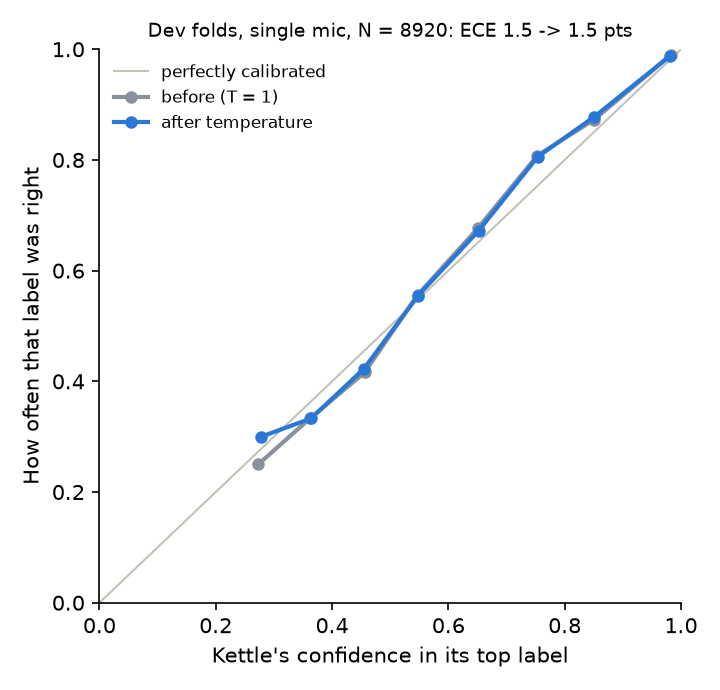

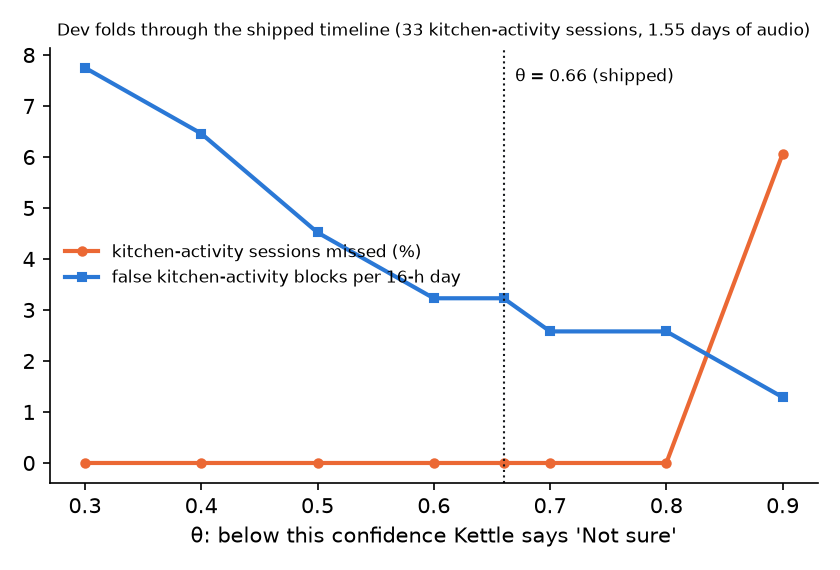

ECE before / after temperature: 1.5 / 1.5 points
theta 0.66 coverage {'value': 85.0, 'split': 'dev folds (also used for selection)', 'n_clips': 8920, 'n_sessions': 257, 'ci95': [81.8, 88.1]} shown-label precision {'value': 90.1, 'split': 'dev folds (also used for selection)', 'n_clips': 8920, 'n_sessions': 257, 'ci95': [86.8, 92.4]}


In [6]:
from IPython.display import Image, display
os.makedirs("results/notebook", exist_ok=True)
reliability_png(R["calibration"], __import__("pathlib").Path("results/notebook/reliability_dev.png"))
tradeoff_png(R["theta_tradeoff"], R["not_sure"]["theta"], __import__("pathlib").Path("results/notebook/theta_tradeoff_dev.png"))
display(Image("results/notebook/reliability_dev.png", width=420)); display(Image("results/notebook/theta_tradeoff_dev.png", width=520))
print("ECE before / after temperature:", R["calibration"]["ece_before"]["value"], "/", R["calibration"]["ece_after_temperature"]["value"], "points")
print("theta", R["not_sure"]["theta"], "coverage", R["not_sure"]["coverage_metric"], "shown-label precision", R["not_sure"]["shown_precision_metric"])

## 6. Slices we can check
SINS is one person in one home, so age and sex can't be tested. Microphone positions and activities can; the team's own kitchens are added on Sunday (`python -m eval --split own-kitchen`).

DevNode1: 84.0 [80.5, 86.3]  N=2214
DevNode2: 86.2 [81.8, 89.1]  N=2281
DevNode3: 86.7 [83.1, 89.2]  N=2193
DevNode4: 84.0 [79.1, 87.1]  N=2232


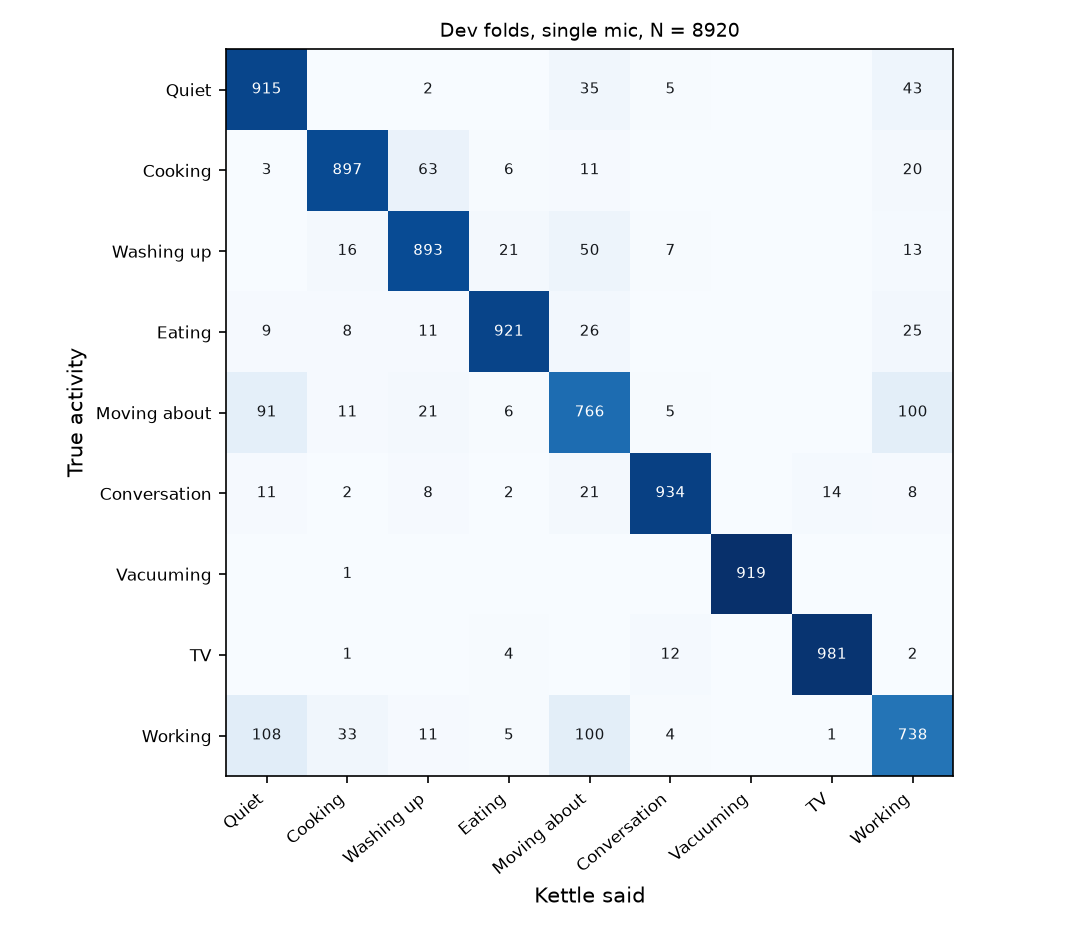

In [7]:
for nd, m in R["per_node"].items():
    print(f"{nd}: {m['value']} [{m['ci95'][0]}, {m['ci95'][1]}]  N={m['n_clips']}")
cm = np.array(R["ours_ch0"]["confusion"])
confusion_png(cm, __import__("pathlib").Path("results/notebook/confusion_dev.png"), f"Dev folds, single mic, N = {R['n_clips']}")
display(Image("results/notebook/confusion_dev.png", width=520))

## 7. The held-out test: the official DCASE 2018 eval sample, run once
Recomputed from the saved predictions (`results/eval_predictions.jsonl`) and the dataset's public labels. The run itself (commit, model hash, time) is recorded in `results/eval_run.json`.

In [8]:
from eval.dcase import score_saved_predictions
if os.path.exists("results/eval_predictions.jsonl"):
    E = score_saved_predictions()
    print(json.dumps(E["slices"], indent=1)[:1500])
    print(json.load(open("results/eval_run.json"))["attempts"])
else:
    print("The held-out run hasn't happened yet.")

{
 "all": {
  "node_avg": {
   "value": 85.3,
   "split": "DCASE 2018 Task 5 eval sample (held-out test, run once)",
   "n_clips": 7791,
   "n_sessions": 91,
   "ci95": [
    75.5,
    88.1
   ]
  },
  "ch0": {
   "value": 84.1,
   "split": "DCASE 2018 Task 5 eval sample (held-out test, run once)",
   "n_clips": 7791,
   "n_sessions": 91,
   "ci95": [
    74.4,
    86.7
   ]
  }
 }
}
[{'started': '2026-11-14 13:04:02 CST', 'commit': '351e929292b81f201608506524272cb2ab9a2ec0', 'head_sha256': 'fa5de76a7970865bddb4bed4206dc2b4145d90eb96d0155d85e402c863c54037', 'preregister_commit': '0119c57f1d683126813529236faa330fc2150563', 'predictions_written': True, 'predictions_at': '2026-11-14 13:04:03 CST', 'ended': '2026-11-14 13:15:09 CST'}]


## 8. Check: do these numbers match `results/metrics.json`?

In [9]:
def same(a, b): return abs(a["value"] - b["value"]) <= 0.1   # the cache stores CED embeddings as float16
checks = {"ours_ch0": same(R["ours_ch0"]["macro_f1"], saved["dev"]["ours_ch0"]["macro_f1"]),
          "ours_node_avg": same(R["ours_node_avg"]["macro_f1"], saved["dev"]["ours_node_avg"]["macro_f1"]),
          "meal caught": same(R["meal_activity"]["caught"], saved["dev"]["meal_activity"]["caught"]),
          "theta": R["not_sure"]["theta"] == saved["dev"]["not_sure"]["theta"]}
for k in ("logmel_lr", "apple_zeroshot", "majority", "ast_zeroshot", "ced_tiny_zeroshot", "clap_zeroshot"):
    if k in R["baselines"] and "macro_f1" in R["baselines"][k] and "macro_f1" in saved["dev"]["baselines"].get(k, {}):
        checks[k] = same(R["baselines"][k]["macro_f1"], saved["dev"]["baselines"][k]["macro_f1"])
print(checks)
print("ALL MATCH (within 0.1 points)" if all(checks.values()) else "MISMATCH: see above")
print(f"notebook ran in {time.time() - T0:.0f} s")

{'ours_ch0': True, 'ours_node_avg': True, 'meal caught': True, 'theta': True, 'logmel_lr': True, 'apple_zeroshot': True, 'majority': True, 'ast_zeroshot': True, 'ced_tiny_zeroshot': True}
ALL MATCH (within 0.1 points)
notebook ran in 69 s
